# EP03｜OLED 和 LCD 差在哪？液晶螢幕為什麼黑不起來

像素腦底加！這是影片裡的「螢幕模擬器」，按上方的 **執行階段 → 全部執行**（或每格按 ▶️）就能自己跑一遍。
我們把同一格電影畫面，丟給液晶（LCD）、mini LED 分區背光、OLED 三種螢幕，看黑色有多黑、光暈在哪、深色模式省多少。

⚠️ 這是簡化的示意模型，用來看懂原理，不是某一款真實螢幕的實測數值。

📺 影片：[youtube.com/@pixelbraintw](https://www.youtube.com/@pixelbraintw)

## 0. 準備：載入套件、下載一張貓咪照片（CC0 授權，作者 AdinaVoicu，Wikimedia Commons）

In [1]:
import os, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from scipy.ndimage import gaussian_filter

if not os.path.exists("cat.png"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/pixelbraintw/pixelbrain-code/main/ep03-oled/cat.png", "cat.png")

def show(*imgs, titles=None, size=5):
    fig, axes = plt.subplots(1, len(imgs), figsize=(size * len(imgs), size * 0.6))
    for i, (ax, im) in enumerate(zip(np.atleast_1d(axes), imgs)):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        if titles: ax.set_title(titles[i])
        ax.axis("off")
    plt.show()

def to_img(x):
    """把光量（0 到 1）換回照片的數字，給人看"""
    return Image.fromarray((np.clip(x, 0, 1) ** (1 / 2.2) * 255).astype(np.uint8))

## 1. 做一格電影畫面

全黑的 640 × 360 畫面，中間貼一隻貓，下面一句白色字幕。

最後一行很重要：照片存的 0 到 255 是照人眼的感覺壓縮過的（伽瑪編碼），不是真正的光量。除以 255 再取 2.2 次方，才是螢幕要發出的光。例如 128 只有大約 22% 的光。

(360, 640, 3)


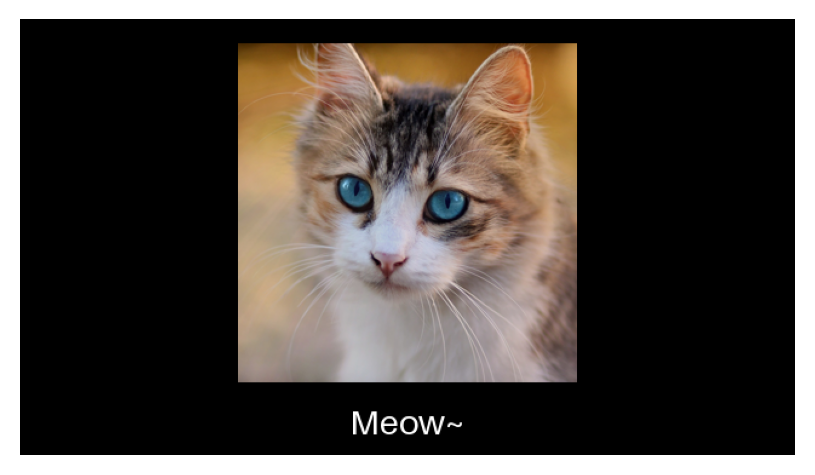

128 → 0.2195197180748679


In [2]:
cat = Image.open("cat.png").convert("RGB").resize((280, 280))
frame = Image.new("RGB", (640, 360))
frame.paste(cat, (180, 20))
ImageDraw.Draw(frame).text((320, 332), "Meow~", fill="white", anchor="mm", font=ImageFont.load_default(28))
L = (np.array(frame) / 255) ** 2.2
print(L.shape)
show(frame)
print("128 →", (128 / 255) ** 2.2)

## 2. 液晶（LCD）和 OLED

液晶：背光全亮，液晶最多擋掉 999/1000，黑色還會漏出 1/1000（對比 1000：1）。
OLED：每個像素自己發光，要多少光就發多少光。

In [3]:
leak = 1 / 1000
lcd = leak + (1 - leak) * L
oled = L
print(lcd.min(), oled.min())

0.001 0.0


## 3. mini LED 分區背光

1. 把畫面切成 40 × 40 的格子，每格的燈跟著格子裡最亮的像素開
2. 燈光穿過擴散板會往外散開，用高斯模糊模擬
3. 液晶把多出來的光擋掉

(9, 16) 68


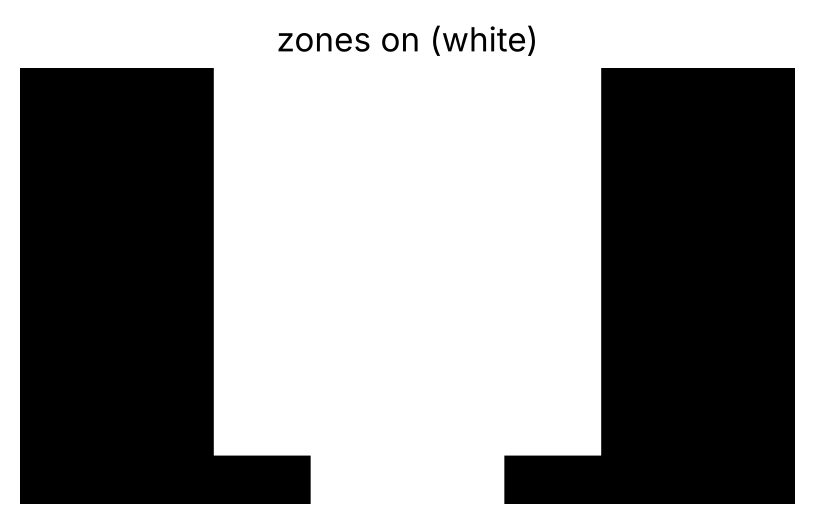

In [4]:
def mini_led(L, zone=40):
    h, w, _ = L.shape
    need = L.max(axis=2).reshape(h // zone, zone, w // zone, zone).max(axis=(1, 3))
    bl = gaussian_filter(np.kron(need, np.ones((zone, zone))), zone / 2)
    lc = np.clip(L / np.maximum(bl, 1e-6)[..., None], 0, 1)
    return bl[..., None] * (leak + (1 - leak) * lc), need

mled, need = mini_led(L)
print(need.shape, (need > 0).sum())
show(np.kron(need > 0, np.ones((40, 40))) * 255, titles=["zones on (white)"])

## 4. 暗房裡眼睛看到的樣子

用對數把暗部拉亮：很暗的光放大兩百多倍，亮的地方幾乎不變，模擬全黑房間裡眼睛適應以後看到的樣子。

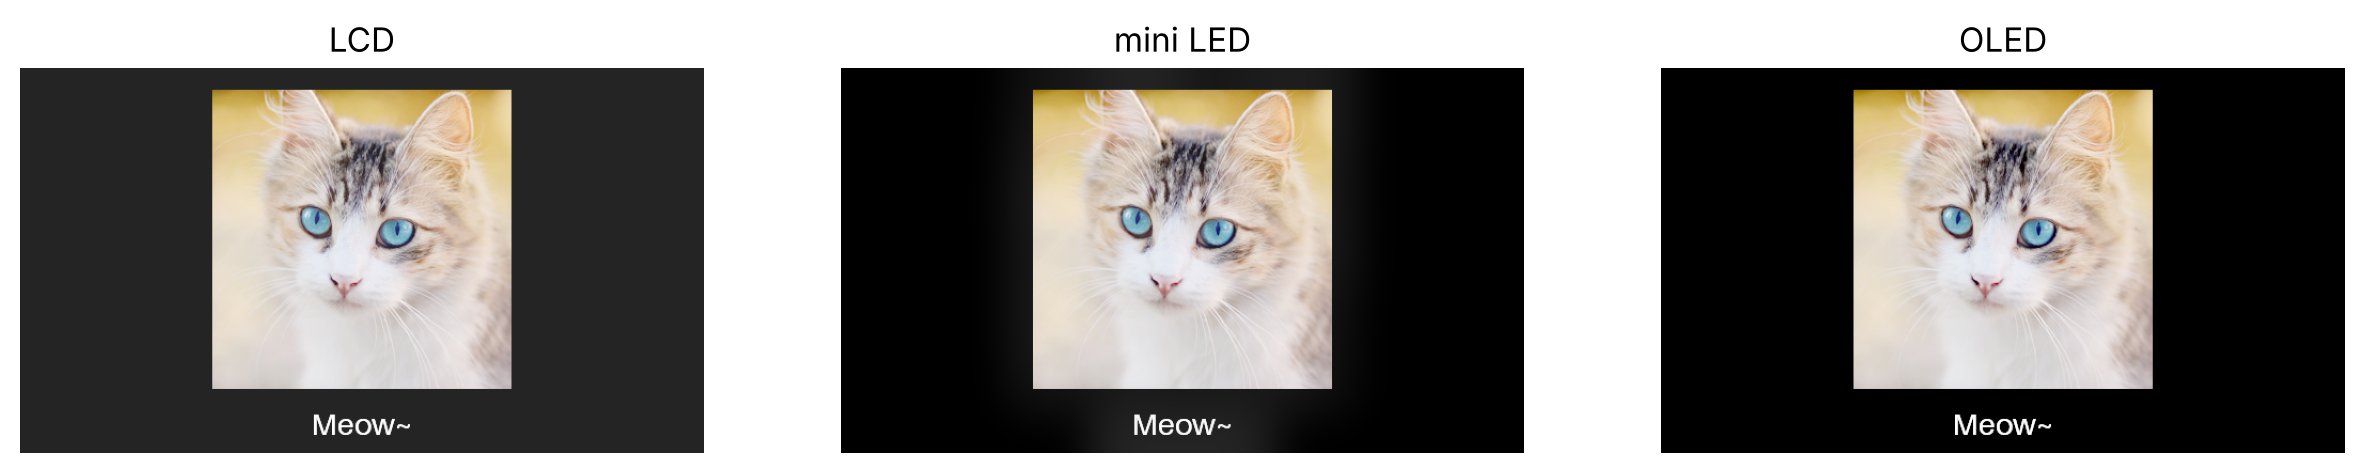

In [5]:
def eye(x, k=2000):
    return Image.fromarray((np.log1p(x * k) / np.log1p(k) * 255).astype(np.uint8))

show(eye(lcd), eye(mled), eye(oled), titles=["LCD", "mini LED", "OLED"])

## 5. 量一量黑色有多黑（白色 = 1000 份光）

In [6]:
far, near = (slice(0, 40), slice(0, 40)), (slice(305, 360), slice(240, 400))
for name, img in [("LCD", lcd), ("mini LED", mled), ("OLED", oled)]:
    a, b = img[far].mean() * 1000, img[near][L[near] == 0].mean() * 1000
    print(f"{name:8s} 角落 {a:.2f}  字幕旁 {b:.2f}")

LCD      角落 1.00  字幕旁 1.00
mini LED 角落 0.00  字幕旁 0.77
OLED     角落 0.00  字幕旁 0.00


## 6. 深色模式省電嗎？

簡化假設：OLED 耗電大約跟畫面發出的光量成正比；液晶的背光不管畫面是什麼都一樣亮。
（真實手機還有處理器、網路在耗電，實際省多少跟螢幕亮度很有關係。）

OLED 深色 / 淺色 = 29%


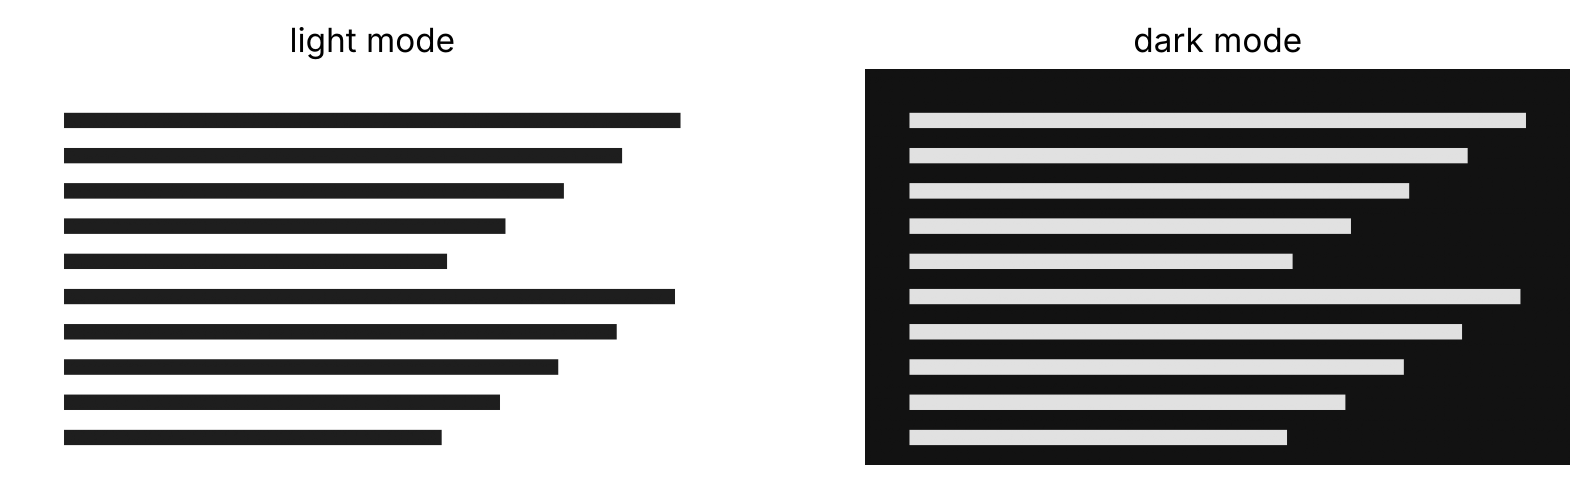

In [7]:
ui = np.zeros((360, 640), bool)
for i, y in enumerate(range(40, 330, 32)):
    ui[y:y + 14, 40:600 - (i * 53) % 260] = True
light = np.where(ui, 30, 255) / 255
dark = np.where(ui, 225, 18) / 255
p_light, p_dark = (light ** 2.2).mean(), (dark ** 2.2).mean()
print(f"OLED 深色 / 淺色 = {p_dark / p_light:.0%}")
show(light * 255, dark * 255, titles=["light mode", "dark mode"])

## 7. 烙印（誇張化的示意模型）

每小時播不同的節目（用亂數畫面代替），右上角的 NEWS 台標一直亮著。
每個像素發多少光就老化多少，藍色老得比較快（這裡設成 2 倍）。播完 2000 小時，換成一整片灰色看看。
真實的 OLED 老化慢很多，而且有像素位移、亮度補償等方法減輕。

[0.2 0.2 0.4] [0.09428289 0.09428289 0.18856579]


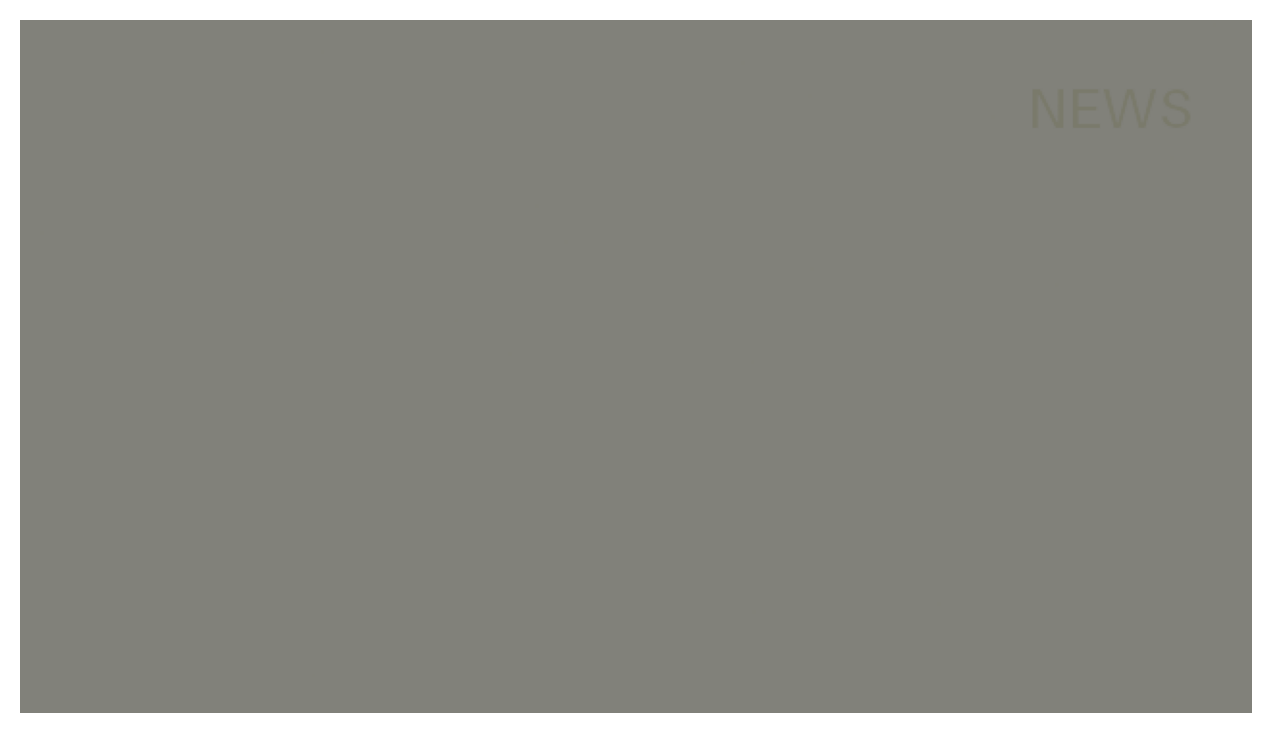

In [8]:
logo = Image.new("L", (640, 360))
ImageDraw.Draw(logo).text((566, 44), "NEWS", fill=255, anchor="mm", font=ImageFont.load_default(30))
logo = np.array(logo)[..., None] / 255
wear = np.zeros((360, 640, 3))
rng = np.random.default_rng(0)
for hour in range(2000):
    tv = np.maximum(rng.uniform(0, 1, (360, 640, 1)), logo)
    wear += tv * 1e-4 * np.array([1, 1, 2])
gray = 0.25 * (1 - wear)
print(wear.max(axis=(0, 1)), wear.min(axis=(0, 1)))
plt.figure(figsize=(8, 4.5)); plt.imshow(to_img(gray)); plt.axis("off"); plt.show()

## 🧪 自己玩玩看

1. 把 `leak` 改成 `1 / 3000`（大約是對比比較高的液晶面板），黑邊會黑多少？
2. 把 `mini_led(L, zone=40)` 改成 `zone=20`（分區變多、變小），光暈會變小嗎？為什麼？
3. 上傳你自己的照片（左邊資料夾圖示 → 上傳），把 `cat.png` 換成你的檔名再跑一次。

有問題歡迎到影片留言區問像素腦！